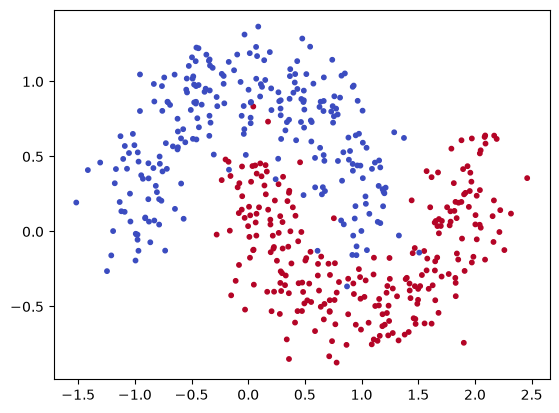

In [86]:
import numpy as np
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X, y = make_moons(n_samples = 500, noise = 0.2, random_state =40)
plt.scatter(X[:,0], X[:,1], c=y, cmap = "coolwarm", s=10)
plt.show()

In [87]:
y = y.reshape(-1,1)
from sklearn.model_selection import train_test_split
X, X_test, y, y_test = train_test_split(X, y, test_size = 0.2, random_state = 30)

The goal is to build a linear classifier $$z = w\cdot x + b$$ by hand, and use sigmoid (transform the data into a probability)
$$a = 1/(1+e^{-z})$$
and binary cross-entropy loss
$$L = -(y\log a + (1-y)\log(1-a))$$
to train. We initialize the parameters as follows

### 1. Sigmoid, Forward Function, Loss

In [88]:
def sigmoid(z):
    return 1.0/(1.0 + np.exp(-z))

In [89]:
def forward(X, w, b):
    z = X@w + b
    a = sigmoid(z)
    return a

In [90]:
def bce_loss(a, y, eps = 1e-12):
    a = np.clip(a, eps, 1-eps)
    return -np.mean(y*np.log(a) + (1-y)*np.log(1-a))

### 2. Gradient Descend

In [91]:
def gradients(X, a, y):
    m = X.shape[0]
    dz = a - y # dL/dz, (m,1)
    dw = X.T @ dz /m # dL/dw, (n,1)
    db = np.mean(dz) # dL/db
    return dw, db

### 3. Training

In [92]:
def train(X, y, lr = 0.5, steps = 1001):
    m, n = X.shape
    rng = np.random.default_rng(20)
    w = rng.normal(0, 0.01, size = (n,1))
    b = 0.0
    
    for step in range(steps):
        a = forward(X, w, b)
        dw, db = gradients(X, a, y)
        w -= lr * dw
        b -= lr * db
        if step%100 == 0:
            loss = bce_loss(a, y)
            acc = np.mean((a>0.5) == y)
            print(f"step {step:4d} loss {loss:4f} accuracy {acc:3f}")  
    return w, b

In [93]:
w, b = train(X, y)

step    0 loss 0.696262 accuracy 0.145000
step  100 loss 0.319336 accuracy 0.847500
step  200 loss 0.304906 accuracy 0.857500
step  300 loss 0.301376 accuracy 0.870000
step  400 loss 0.300260 accuracy 0.872500
step  500 loss 0.299863 accuracy 0.872500
step  600 loss 0.299713 accuracy 0.872500
step  700 loss 0.299653 accuracy 0.872500
step  800 loss 0.299629 accuracy 0.872500
step  900 loss 0.299619 accuracy 0.872500
step 1000 loss 0.299615 accuracy 0.872500


### 4. Boundary

In [94]:
def plot_decision_boundary(predict, X, y, steps = 300, pad = 0.5):
    # predict is a function that sends X to the predicted probability that y=1

    # build a grid with some padding
    x_min, x_max = X[:,0].min() - pad, X[:,0].max() + pad
    y_min, y_max = X[:,1].min() - pad, X[:,1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, steps), np.linspace(y_min, y_max, steps))

    # reshape to (N, 2) array, predict and reshape back
    grid = np.c_[xx.ravel(),yy.ravel()]
    probs = predict(grid).reshape(xx.shape)

    # draw
    plt.contourf(xx, yy, probs, levels = 50, cmap = "coolwarm", alpha = 0.6)
    plt.contour(xx, yy, probs, levels = [0.5], colors = "black", linewidths =  1.5)
    plt.scatter(X[:,0], X[:,1], c = y.ravel(), cmap = "coolwarm", edgecolors = "k", linewidths = 0.3, s = 15)
    plt.xlabel("x1")
    plt.xlabel("x2")
    plt.title("Logistic regression decision boundary")
    plt.show

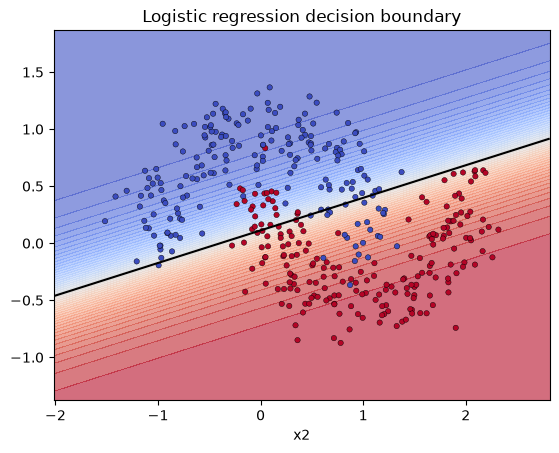

In [95]:
plot_decision_boundary(lambda P: forward(P, w, b), X, y)

### 5. Test Errors

In [96]:
Test_acc = np.mean((forward(X_test, w, b)>0.5) == y_test)
print(f"Training accuracy is {acc:3f} and test accuracy is {Test_acc:3f}")

Training accuracy is 0.872500 and test accuracy is 0.850000


### 4. More Features
Adding features up to cubic.

step    0 loss 0.695264 accuracy 0.350000
step  100 loss 0.234194 accuracy 0.905000
step  200 loss 0.194801 accuracy 0.930000
step  300 loss 0.173333 accuracy 0.942500
step  400 loss 0.159143 accuracy 0.945000
step  500 loss 0.148917 accuracy 0.945000
step  600 loss 0.141137 accuracy 0.950000
step  700 loss 0.134985 accuracy 0.952500
step  800 loss 0.129977 accuracy 0.960000
step  900 loss 0.125807 accuracy 0.962500
step 1000 loss 0.122271 accuracy 0.962500


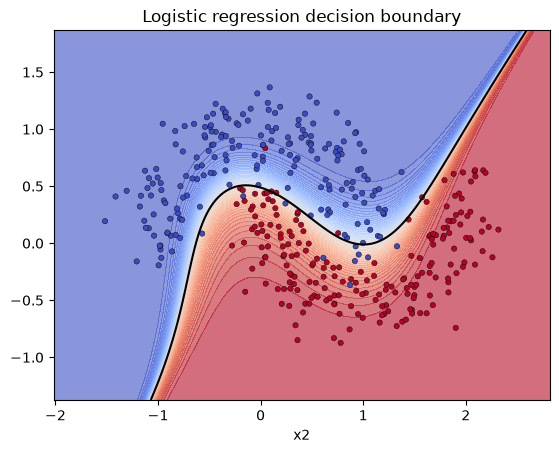

In [97]:
X_new = np.c_[X, X[:, 0]**2, X[:, 1]**2, X[:, 0]*X[:, 1], X[:, 0]**3, X[:, 1]**3]
w, b = train(X_new, y)
plot_decision_boundary(lambda P: forward(np.c_[P, P[:, 0]**2, P[:, 1]**2, P[:, 0]*P[:, 1], P[:, 0]**3, P[:, 1]**3], w, b), X_new, y)